<a href="https://colab.research.google.com/github/usamamuhamad/smart-video-analytics/blob/main/week1_opencv_basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1: OpenCV Basics

Image ka size: (300, 300, 3)


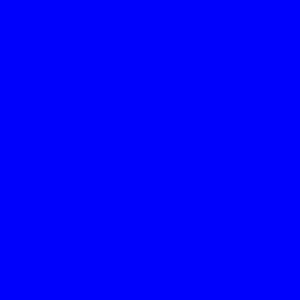

In [4]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# 300x300 ki ek neeli tasveer banate hain
img = np.zeros((300, 300, 3), dtype=np.uint8)
img[:] = (255, 0, 0)   # OpenCV mein rang BGR hota hai, to ye neela hai

print("Image ka size:", img.shape)
cv2_imshow(img)

In [5]:
from google.colab import files

uploaded = files.upload()
video_path = list(uploaded.keys())[0]
print("people walk:", video_path)

Saving 14782389_3840_2160_60fps.mp4 to 14782389_3840_2160_60fps.mp4
people walk: 14782389_3840_2160_60fps.mp4


Video khuli? True
FPS: 60.0
Size: 3840 x 2160
Total frames: 1020


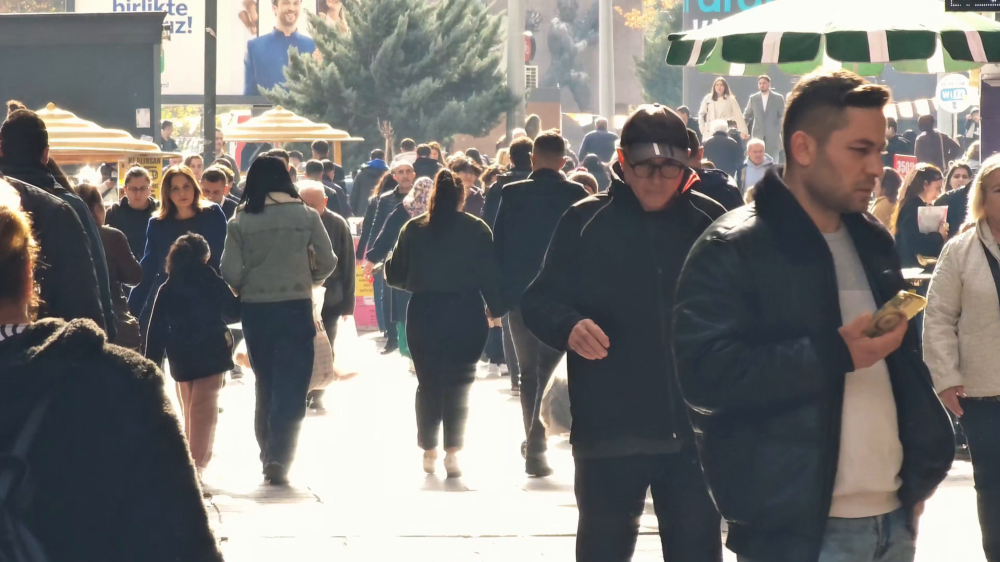

In [6]:
import cv2
from google.colab.patches import cv2_imshow

cap = cv2.VideoCapture(video_path)
print("Video khuli?", cap.isOpened())

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("FPS:", fps)
print("Size:", width, "x", height)
print("Total frames:", total)

ok, frame = cap.read()   # pehla frame parho
if ok:
    cv2_imshow(frame)

cap.release()

Frame number: 0 | size: (720, 1280, 3)


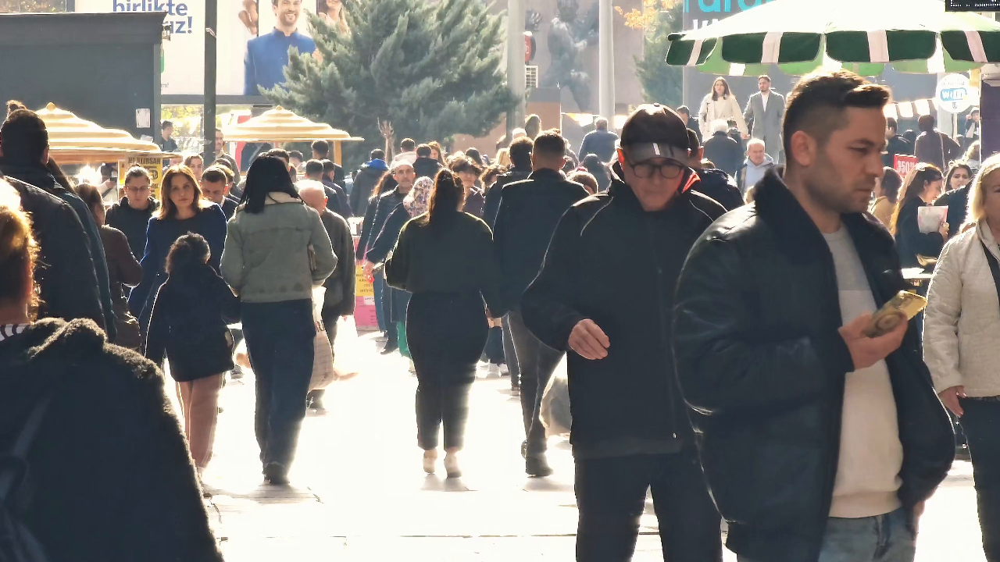

Frame number: 200 | size: (720, 1280, 3)


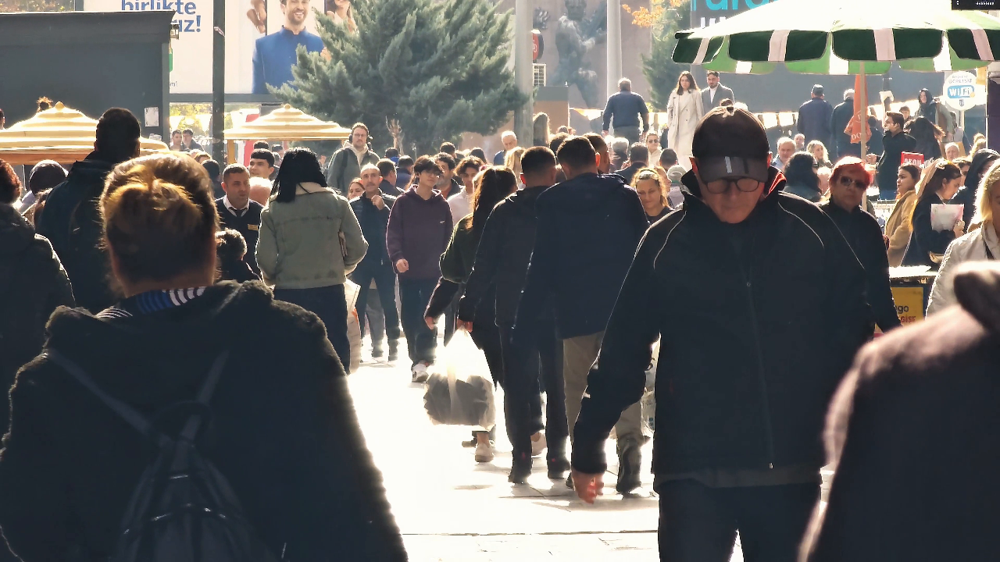

Frame number: 400 | size: (720, 1280, 3)


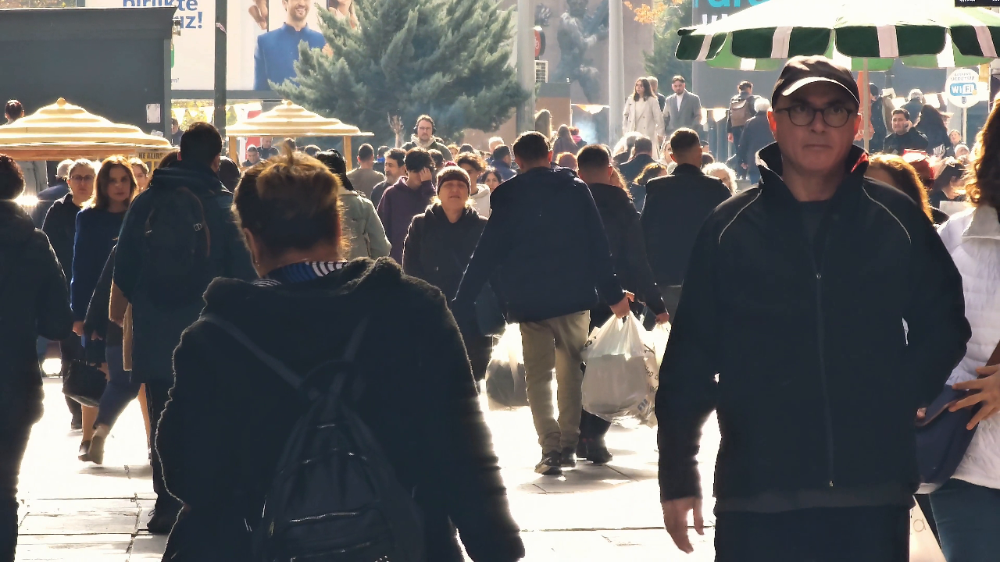

Frame number: 600 | size: (720, 1280, 3)


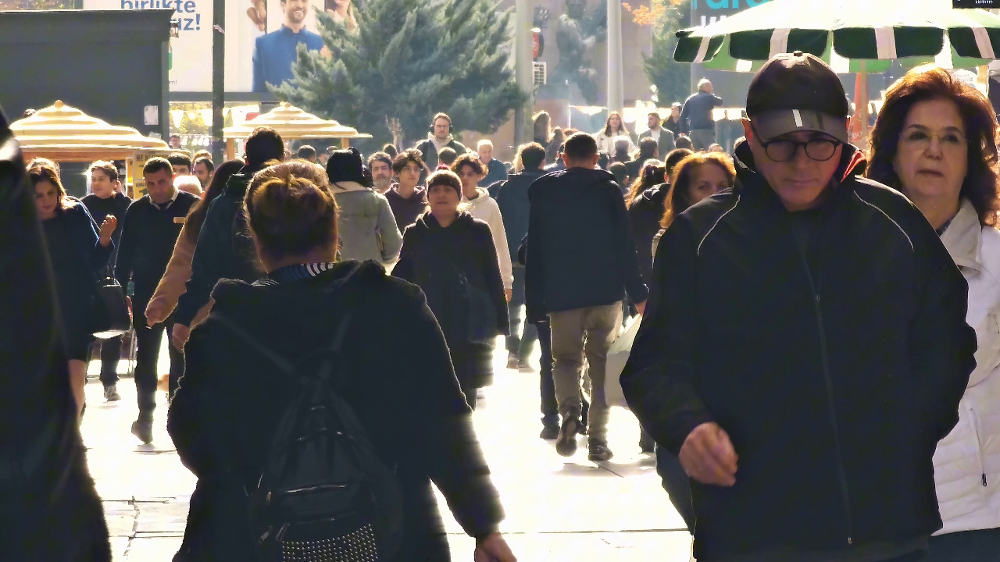

Frame number: 800 | size: (720, 1280, 3)


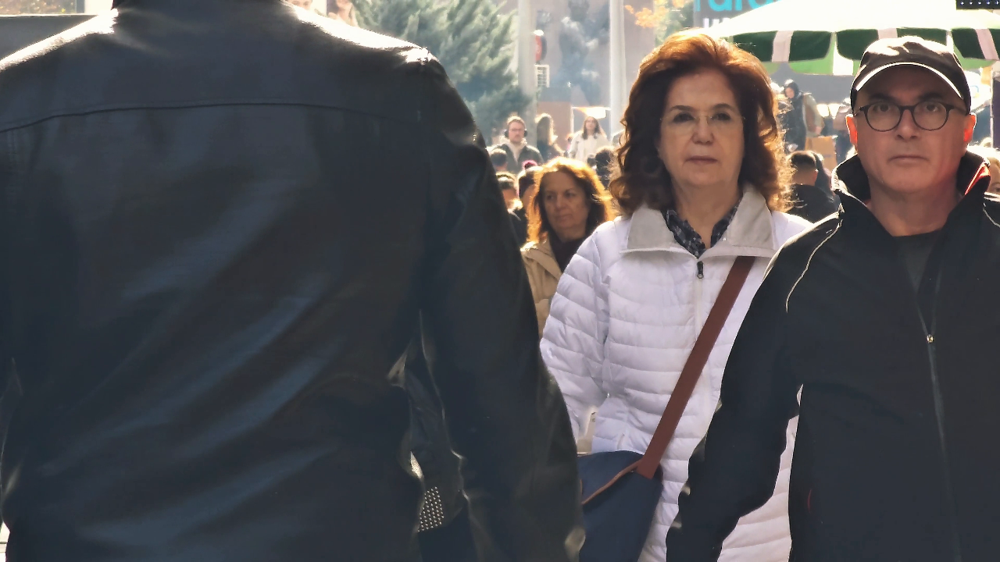

Frame number: 1000 | size: (720, 1280, 3)


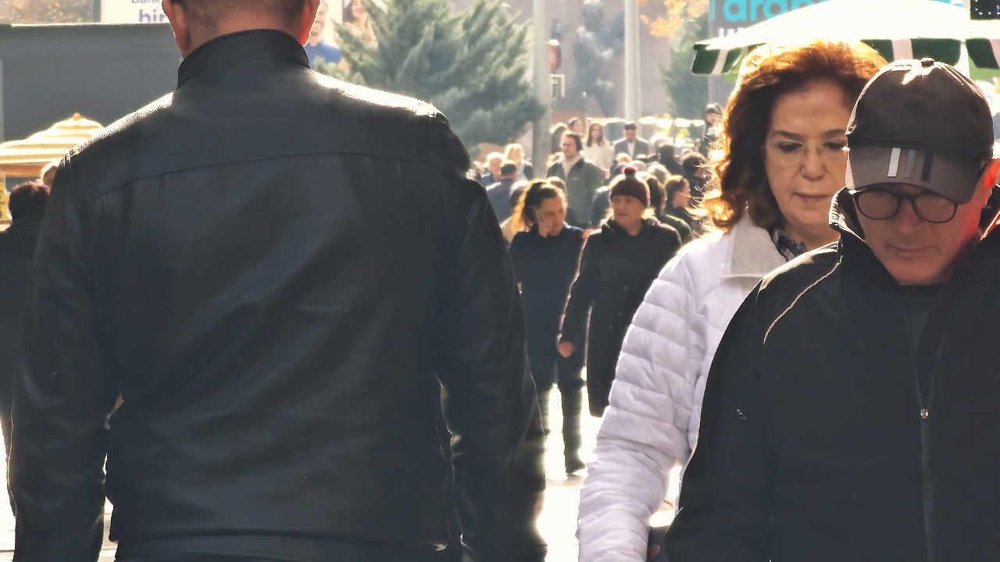

Kul frames parhe: 1020


In [7]:
import cv2
from google.colab.patches import cv2_imshow

cap = cv2.VideoCapture(video_path)

frame_number = 0

while True:
    ok, frame = cap.read()      # agla frame parho
    if not ok:                  # video khatam to ruk jao
        break

    # frame ko chhota karo (1280 chaurai, lambai khud theek hogi)
    small = cv2.resize(frame, (1280, 720))

    # har 200wen frame ko screen par dikhao
    if frame_number % 200 == 0:
        print("Frame number:", frame_number, "| size:", small.shape)
        cv2_imshow(small)

    frame_number += 1

cap.release()
print("Kul frames parhe:", frame_number)

In [8]:
import cv2

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)

# nayi video ki settings (1280x720)
out = cv2.VideoWriter("output.mp4",
                      cv2.VideoWriter_fourcc(*"mp4v"),
                      fps,
                      (1280, 720))

frame_number = 0

while True:
    ok, frame = cap.read()
    if not ok:
        break

    frame = cv2.resize(frame, (1280, 720))

    # 1) ek hara box (rectangle) banao
    cv2.rectangle(frame, (400, 200), (800, 600), (0, 255, 0), 3)

    # 2) ek laal line banao (aage line-crossing ke kaam aayegi)
    cv2.line(frame, (0, 360), (1280, 360), (0, 0, 255), 3)

    # 3) frame number likho
    cv2.putText(frame, f"Frame: {frame_number}", (30, 60),
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255, 255, 255), 3)

    out.write(frame)          # frame nayi video mein save karo
    frame_number += 1

cap.release()
out.release()
print("Video save ho gayi: output.mp4, frames:", frame_number)

Video save ho gayi: output.mp4, frames: 1020


In [9]:
from google.colab import files
files.download("output.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>